# Exploração textual

[▶ Abrir este notebook no Google Colab](https://colab.research.google.com/github/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_04/02_exploracao_textual.ipynb)

O Notebook 01 descreveu a composição e as medidas documentais da base. Agora
voltaremos ao conteúdo linguístico dos registros, começando pelas regras que
transformam texto preservado em unidades analisáveis.

## Tokenização e normalização

![O texto preservado passa por normalização, tokenização, filtro e contagem; o diagrama indica possíveis perdas em cada transformação.](imagens/02_fluxo_tokenizacao.svg)

Tokenizar segmenta por regra. Minúsculas, pontuação e stopwords podem apagar distinções; preserve o texto e documente decisões. Neste exemplo, os tokens são calculados separadamente por documento para não criar contextos ou n-gramas entre o fim de um texto e o início do seguinte.

In [1]:
# @title Preparação do ambiente — execute esta célula no Google Colab
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

URL_REPOSITORIO = 'https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais.git'
REPOSITORIO = Path(
    "/content/disciplina_computacao_aplicada_humanidades_digitais"
)
PASTA_UNIDADE = REPOSITORIO / 'unidade_04'

try:
    import google.colab  # type: ignore  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    if not (REPOSITORIO / ".git").exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                "main",
                URL_REPOSITORIO,
                str(REPOSITORIO),
            ],
            check=True,
        )

    PACOTES_COLAB = []
    ausentes = [
        especificacao
        for modulo, especificacao in PACOTES_COLAB
        if importlib.util.find_spec(modulo) is None
    ]
    if ausentes:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *ausentes],
            check=True,
        )

    os.chdir(PASTA_UNIDADE)
    print("Ambiente preparado em:", Path.cwd())
else:
    print("Ambiente local: nenhuma clonagem necessária.")

Ambiente local: nenhuma clonagem necessária.


In [2]:
import math
import re
from collections import Counter

import pandas as pd
import sys
from pathlib import Path
from IPython.display import display
sys.path.insert(0, str(Path.cwd())) if str(Path.cwd()) not in sys.path else None
from graficos import ttr_duplo

dados = pd.read_csv("dados/documentos.csv")

def tokenizar(texto):
    return re.findall(r"[a-záàâãéêíóôõúç]+", texto.lower())

dados["tokens"] = dados["texto"].map(tokenizar)
todos_tokens = [token for documento in dados["tokens"] for token in documento]
dados[["id_documento", "tokens"]].head(2)

,id_documento,tokens
0,D001,"[a, escola, noturna, amplia, a, instrução, púb..."
1,D002,"[o, trabalho, nas, oficinas, reúne, jornada, s..."


A tokenização transforma cada documento em unidades contáveis. Como as regras
de segmentação e normalização definem o que será reconhecido como token, elas
precisam ser declaradas antes de qualquer frequência.

## Frequências absoluta e relativa

Se $t_i$ é o token na posição $i$, a frequência de uma palavra $w$ é:

$$
f(w)=\sum_{i=1}^{N}\mathbf{1}(t_i=w),
\qquad
p(w)=\frac{f(w)}{N}.
$$

O valor de $p(w)$ só é interpretável quando $N$ está declarado. Neste
experimento mostraremos dois denominadores:

| Medida | Denominador |
|---|---|
| frequência relativa entre todos os tokens | $N$, antes de retirar stopwords |
| frequência relativa entre tokens de conteúdo | $N_c$, depois de retirar stopwords |

Remover stopwords apenas da tabela, mas manter $N$ como denominador, responde a
uma pergunta diferente de recalcular a proporção dentro do vocabulário filtrado.

In [3]:
stopwords = {"a", "o", "e", "de", "do", "da", "como", "em", "nas", "um", "uma", "também"}
frequencias = Counter(todos_tokens)
tokens_conteudo = [token for token in todos_tokens if token not in stopwords]
frequencias_conteudo = Counter(tokens_conteudo)
total_tokens = len(todos_tokens)
total_tokens_conteudo = len(tokens_conteudo)

tabela_frequencias = pd.DataFrame([
    {
        "palavra": palavra,
        "frequencia": frequencia,
        "relativa_todos_tokens": frequencia / total_tokens,
        "relativa_tokens_conteudo": frequencia / total_tokens_conteudo,
    }
    for palavra, frequencia in frequencias_conteudo.most_common(12)
])
tabela_frequencias

,palavra,frequencia,relativa_todos_tokens,relativa_tokens_conteudo
0,escola,24,0.025641,0.04
1,noturna,24,0.025641,0.04
2,amplia,24,0.025641,0.04
3,instrução,24,0.025641,0.04
4,pública,24,0.025641,0.04
5,ensino,24,0.025641,0.04
6,social,24,0.025641,0.04
7,trabalho,24,0.025641,0.04
8,oficinas,24,0.025641,0.04
9,reúne,24,0.025641,0.04


As frequências mostram quanto um termo aparece, mas retiram as ocorrências de
seus contextos. Para avaliar o sentido e a relevância de uma contagem, precisamos
retornar aos documentos que a produziram.

## Concordâncias

Uma concordância recupera uma janela de $j$ tokens à esquerda e à direita de
cada ocorrência. Não é necessário transformar essa operação em uma medida única:
seu papel é devolver contexto ao agregado. As janelas devem respeitar as fronteiras
dos documentos e conservar o identificador da fonte.

In [4]:
def concordancias(tabela, alvo, janela=4):
    resultados = []
    for _, documento in tabela.iterrows():
        tokens = documento["tokens"]
        for posicao, token in enumerate(tokens):
            if token == alvo:
                inicio = max(0, posicao - janela)
                fim = min(len(tokens), posicao + janela + 1)
                resultados.append({
                    "id_documento": documento["id_documento"],
                    "contexto": " ".join(tokens[inicio:fim]),
                })
    return pd.DataFrame(resultados)

concordancias(dados, "trabalho", janela=4).head(8)

,id_documento,contexto
0,D001,o ensino social o trabalho nas oficinas reúne ...
1,D002,o trabalho nas oficinas reúne jornada
2,D002,e também conflito o trabalho nas oficinas reún...
3,D005,o ensino social o trabalho nas oficinas reúne ...
4,D005,o ensino social o trabalho nas oficinas reúne ...
5,D006,o trabalho nas oficinas reúne jornada
6,D006,e também conflito o trabalho nas oficinas reún...
7,D006,e também conflito o trabalho nas oficinas reún...


As concordâncias permitem examinar manualmente o entorno de uma palavra. O
passo seguinte sistematiza uma pergunta relacionada: quais unidades aparecem
juntas de maneira recorrente dentro dos documentos?

## N-gramas e colocações

![A frequência do bigrama é comparada às frequências marginais; o resultado deve ser examinado com frequência mínima e concordâncias.](imagens/02_anatomia_pmi.svg)

Um bigrama é o par adjacente $(t_i,t_{i+1})$ dentro de um mesmo documento.
Para comparar a frequência conjunta com as frequências marginais das posições
esquerda e direita, usaremos informação mútua pontual:

$$
PMI(a,b)=\log_2\left(\frac{P(a,b)}{P_L(a)P_R(b)}\right)
=\log_2\left(\frac{c(a,b)\,N_b}{c_L(a)c_R(b)}\right).
$$

| Símbolo | Significado |
|---|---|
| $c(a,b)$ | frequência do bigrama $(a,b)$ |
| $N_b$ | total de bigramas dentro dos documentos |
| $c_L(a)$ | ocorrências de $a$ na posição esquerda dos bigramas |
| $c_R(b)$ | ocorrências de $b$ na posição direita dos bigramas |

PMI alto indica associação acima do esperado pelas marginais; não indica
causalidade, importância histórica ou estabilidade. Como a medida favorece eventos
raros, exigiremos frequência mínima e retornaremos às concordâncias.

In [5]:
bigramas = Counter()
marginal_esquerda = Counter()
marginal_direita = Counter()

for tokens_documento in dados["tokens"]:
    pares_documento = list(zip(tokens_documento, tokens_documento[1:]))
    bigramas.update(pares_documento)
    marginal_esquerda.update(a for a, _ in pares_documento)
    marginal_direita.update(b for _, b in pares_documento)

total_bigramas = sum(bigramas.values())
frequencia_minima = 3
linhas_pmi = []
for (a, b), frequencia in bigramas.items():
    if frequencia >= frequencia_minima:
        pmi = math.log2(
            frequencia * total_bigramas
            / (marginal_esquerda[a] * marginal_direita[b])
        )
        linhas_pmi.append((f"{a} {b}", frequencia, pmi))

tabela_colocacoes = pd.DataFrame(
    sorted(linhas_pmi, key=lambda linha: linha[2], reverse=True),
    columns=["bigrama", "frequencia", "pmi"],
)
tabela_colocacoes.head(10)

,bigrama,frequencia,pmi
0,escola noturna,24,5.247928
1,noturna amplia,24,5.247928
2,instrução pública,24,5.247928
3,ensino social,24,5.247928
4,trabalho nas,24,5.247928
5,nas oficinas,24,5.247928
6,oficinas reúne,24,5.247928
7,reúne jornada,24,5.247928
8,jornada salário,24,5.247928
9,máquina anunciam,24,5.247928


N-gramas e PMI observam relações locais entre palavras. Agora mudaremos a
escala: em vez de pares de tokens, compararemos o repertório lexical de documentos
inteiros e verificaremos como o tamanho textual interfere nessa comparação.

## Vocabulário e diversidade lexical

Se $V_d$ é o número de formas distintas e $N_d$ o número de tokens do
documento $d$, a razão forma–token é:

$$
TTR(d)=\frac{V_d}{N_d}.
$$

Como a TTR tende a cair quando o texto cresce, podemos comparar segmentos de
tamanho fixo $m$:

$$
TTR_m(d)=\frac{\left|\{t_1,\ldots,t_m\}\right|}{m},
\qquad N_d\geq m.
$$

Para que todos os 24 documentos participem, adotaremos como $m$ o tamanho do
menor texto da base. Usar os primeiros $m$ tokens controla o tamanho, mas ainda é
sensível à posição do trecho; projetos reais devem comparar segmentos ou amostras
com um protocolo explícito.

Tamanho comum adotado: 19 tokens


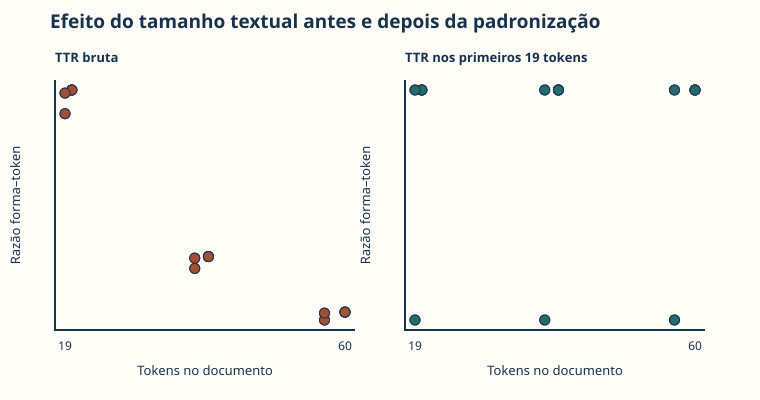

,id_documento,tokens,formas,ttr,ttr_19
0,D001,20,17,0.850000,0.842105
1,D002,38,16,0.421053,0.842105
2,D003,57,15,0.263158,0.789474
3,D004,20,17,0.850000,0.842105
4,D005,40,17,0.425000,0.842105


In [6]:
tamanho_padrao = int(dados["tokens"].map(len).min())

def ttr_padronizada(tokens, tamanho):
    if len(tokens) < tamanho:
        return pd.NA
    segmento = tokens[:tamanho]
    return len(set(segmento)) / tamanho

diversidade = pd.DataFrame({
    "id_documento": dados["id_documento"],
    "tokens": dados["tokens"].map(len),
    "formas": dados["tokens"].map(lambda tokens: len(set(tokens))),
    "ttr": dados["tokens"].map(lambda tokens: len(set(tokens)) / len(tokens)),
    f"ttr_{tamanho_padrao}": dados["tokens"].map(
        lambda tokens: ttr_padronizada(tokens, tamanho_padrao)
    ),
})
print("Tamanho comum adotado:", tamanho_padrao, "tokens")

display(ttr_duplo(
    diversidade["tokens"].tolist(),
    diversidade["ttr"].tolist(),
    diversidade[f"ttr_{tamanho_padrao}"].tolist(),
    tamanho_padrao,
))
diversidade.head()

## Aplicação ao projeto Goodreads

As células seguintes repetem as operações do notebook com a base derivada da
Unidade 3. A especificação principal de gênero da autoria é **E2** (rótulo
original, excluindo os 1.274 livros com rótulo duvidoso). E1 (rótulo original)
e E3 (duvidosos reclassificados como feminino) aparecem como sensibilidade.
Cada tabela informa a especificação e o denominador.

In [7]:
# Localiza a pasta do projeto Goodreads (localmente ou no Colab, se a pasta for enviada para /content)
import sys
from pathlib import Path

CANDIDATOS = [Path("../projeto_goodreads"), Path("projeto_goodreads"), Path("/content/projeto_goodreads")]
PROJETO = next((c.resolve() for c in CANDIDATOS if (c / "preparar_base.py").exists()), None)
if PROJETO is None:
    raise FileNotFoundError(
        "Pasta projeto_goodreads não encontrada. Coloque-a ao lado das pastas unidade_0X "
        "ou, no Colab, envie-a para /content."
    )
if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))
print("Projeto localizado:", (PROJETO / "preparar_base.py").exists())
from preparar_base import carregar_base_analitica
import numpy as np
import pandas as pd
from IPython.display import display

base = carregar_base_analitica()
ESPEC = {"E1 original": "genero_E1_original",
         "E2 sem duvidosos (principal)": "genero_E2_sem_duvidosos",
         "E3 reclassificada": "genero_E3_reclassificado"}
GRUPO = "genero_E2_sem_duvidosos"   # especificação principal
e2 = base[base[GRUPO].notna()].copy()
print("Livros na base:", len(base), "| livros na especificação principal (E2):", len(e2))

Projeto localizado: True
Livros na base: 10454 | livros na especificação principal (E2): 9180


**Tokenização e normalização dos títulos.**

In [8]:
import re
import math
from collections import Counter

STOPWORDS_EN = {"the", "a", "an", "of", "and", "in", "to", "for", "on", "at", "with", "from",
                "by", "my", "your", "is", "or", "her", "his", "our", "their", "its", "be",
                "as", "into", "about", "this", "that", "what", "how", "who", "when", "you",
                "me", "i", "it", "not", "no", "all", "one", "s", "de", "la", "el", "le"}

def tokenizar(texto):
    """Letras de qualquer alfabeto; minúsculas; números e pontuação descartados."""
    return re.findall(r"[^\W\d_]+", str(texto).casefold())

e2["tokens"] = e2["titulo"].map(tokenizar)
e2["tokens_conteudo"] = e2["tokens"].map(lambda ts: [t for t in ts if t not in STOPWORDS_EN])
print("Tokens por título: média", round(e2["tokens"].map(len).mean(), 2), "| mediana", e2["tokens"].map(len).median())
e2[["id_livro", "titulo", "tokens", "tokens_conteudo"]].head(4)

Tokens por título: média 4.01 | mediana 3.0


,id_livro,titulo,tokens,tokens_conteudo
0,686717,Murder on St. Mark's Place,"[murder, on, st, mark, s, place]","[murder, st, mark, place]"
1,2429135,The Girl with the Dragon Tattoo,"[the, girl, with, the, dragon, tattoo]","[girl, dragon, tattoo]"
2,27833684,Tailored for Trouble,"[tailored, for, trouble]","[tailored, trouble]"
3,382975,The Obscene Bird of Night,"[the, obscene, bird, of, night]","[obscene, bird, night]"


**Frequências absolutas e relativas por grupo**, com dois denominadores (todos os tokens e tokens de conteúdo).

In [9]:
tabelas = []
for grupo, dados in e2.groupby(GRUPO):
    todos = [t for ts in dados["tokens"] for t in ts]
    conteudo = [t for ts in dados["tokens_conteudo"] for t in ts]
    contagem = Counter(conteudo)
    tabela = pd.DataFrame(contagem.most_common(15), columns=["termo", "frequencia"])
    tabela["relativa_todos_tokens"] = (tabela["frequencia"] / len(todos)).round(4)
    tabela["relativa_tokens_conteudo"] = (tabela["frequencia"] / len(conteudo)).round(4)
    tabela["titulos_do_grupo"] = len(dados)
    tabela.insert(0, "grupo", grupo)
    print(f"{grupo}: N = {len(todos)} tokens; Nc = {len(conteudo)} tokens de conteúdo; {len(dados)} títulos")
    tabelas.append(tabela)
frequencias_titulos = pd.concat(tabelas, ignore_index=True)
frequencias_titulos

feminino: N = 16608 tokens; Nc = 11409 tokens de conteúdo; 4638 títulos
masculino: N = 20223 tokens; Nc = 13579 tokens de conteúdo; 4542 títulos


,grupo,termo,frequencia,relativa_todos_tokens,relativa_tokens_conteudo,titulos_do_grupo
0,feminino,love,121,0.0073,0.0106,4638
1,feminino,life,90,0.0054,0.0079,4638
2,feminino,girl,80,0.0048,0.0070,4638
3,feminino,vol,67,0.0040,0.0059,4638
4,feminino,story,50,0.0030,0.0044,4638
5,feminino,dark,49,0.0030,0.0043,4638
6,feminino,secret,45,0.0027,0.0039,4638
7,feminino,blood,43,0.0026,0.0038,4638
8,feminino,heart,43,0.0026,0.0038,4638
9,feminino,other,40,0.0024,0.0035,4638


**Contraste entre grupos**: proporção de títulos que contêm cada termo (denominador: títulos do grupo).

In [10]:
# Proporção de títulos que contêm o termo, por grupo (denominador: títulos do grupo)
def proporcao_titulos(termo):
    return e2.groupby(GRUPO)["tokens"].apply(lambda s: s.map(lambda ts: termo in ts).mean())

termos = ["love", "girl", "night", "dead", "war", "heart", "king", "man", "woman", "life", "world", "secret"]
contraste = pd.DataFrame({t: proporcao_titulos(t) for t in termos}).T
contraste["razao_fem_masc"] = (contraste["feminino"] / contraste["masculino"]).round(2)
contraste.round(4).sort_values("razao_fem_masc")

genero_E2_sem_duvidosos,feminino,masculino,razao_fem_masc
war,0.0028,0.0189,0.15
man,0.0041,0.0165,0.25
world,0.0052,0.0176,0.29
life,0.0192,0.0229,0.84
dead,0.0045,0.0053,0.86
night,0.0075,0.0064,1.18
king,0.0067,0.0044,1.52
love,0.0257,0.0117,2.20
secret,0.0097,0.0044,2.20
heart,0.0093,0.0042,2.22


**Concordâncias de *girl*** (janela de 3 tokens, dentro de cada título).

In [11]:
def concordancias(tabela, alvo, janela=3):
    linhas = []
    for _, livro in tabela.iterrows():
        tokens = livro["tokens"]
        for posicao, token in enumerate(tokens):
            if token == alvo:
                inicio, fim = max(0, posicao - janela), min(len(tokens), posicao + janela + 1)
                linhas.append({"id_livro": livro["id_livro"], "grupo": livro[GRUPO],
                               "genero_1": livro["genero_1"], "contexto": " ".join(tokens[inicio:fim])})
    return pd.DataFrame(linhas)

conc_girl = concordancias(e2, "girl")
print("Ocorrências de 'girl':", len(conc_girl))
display(pd.crosstab(conc_girl["genero_1"], conc_girl["grupo"]).sort_values("feminino", ascending=False).head(8))
conc_girl.sample(10, random_state=7).sort_values("grupo")

Ocorrências de 'girl': 98


grupo,feminino,masculino
genero_1,,
Young Adult,19,3
Historical,12,2
Fantasy,11,0
Nonfiction,7,0
Fiction,6,6
Romance,4,0
Mystery,3,1
Autobiography,2,0


,id_livro,grupo,genero_1,contexto
20,16119079,feminino,Romance,forever my girl
70,26156468,feminino,Historical,the girl from the savoy
77,28259094,feminino,Young Adult,manic pixie dream girl
62,722939,feminino,Historical,josefina an american girl
94,16060862,feminino,Travel,boat girl a memoir of
54,10429092,feminino,Fantasy,the girl of fire and
37,40951400,feminino,Romance,the tenth girl
26,9166877,feminino,Young Adult,the girl in the steel
65,3316734,feminino,Young Adult,girl from mars
15,3525895,masculino,Fiction,the girl she used to


**Bigramas e PMI** (bigramas dentro de cada título; frequência mínima declarada).

In [12]:
bigramas, esquerda, direita = Counter(), Counter(), Counter()
for tokens in e2["tokens"]:              # bigramas só dentro de cada título
    pares = list(zip(tokens, tokens[1:]))
    bigramas.update(pares)
    esquerda.update(a for a, _ in pares)
    direita.update(b for _, b in pares)

total_bigramas = sum(bigramas.values())
frequencia_minima = 8
linhas_pmi = []
for (a, b), freq in bigramas.items():
    if freq >= frequencia_minima and a not in STOPWORDS_EN and b not in STOPWORDS_EN:
        pmi = math.log2(freq * total_bigramas / (esquerda[a] * direita[b]))
        linhas_pmi.append((f"{a} {b}", freq, round(pmi, 2)))
print("Total de bigramas:", total_bigramas, "| frequência mínima:", frequencia_minima)
pd.DataFrame(sorted(linhas_pmi, key=lambda l: l[2], reverse=True), columns=["bigrama", "frequencia", "pmi"]).head(12)

Total de bigramas: 27657 | frequência mínima: 8


,bigrama,frequencia,pmi
0,boxed set,10,10.53
1,don t,23,9.08
2,war ii,9,8.47
3,selected poems,11,8.18
4,civil war,12,8.05
5,we were,8,8.00
6,collected poems,8,7.65
7,can t,8,7.50
8,true story,25,7.00
9,other stories,17,6.29


**Diversidade lexical** com amostras de tamanho fixo.

In [13]:
# TTR por título é quase sempre 1 (títulos curtos). Comparamos o vocabulário dos
# grupos com amostras de tamanho fixo: m tokens sorteados de títulos inteiros,
# repetido 200 vezes, para que o tamanho do grupo não decida o resultado.
rng = np.random.default_rng(20261015)
m = 3000
print("TTR por título, média:", round(e2["tokens"].map(lambda ts: len(set(ts)) / len(ts) if ts else np.nan).mean(), 3))

def ttr_amostral(tokens_por_titulo, m, repeticoes=200):
    valores = []
    titulos = list(tokens_por_titulo)
    for _ in range(repeticoes):
        ordem = rng.permutation(len(titulos))
        amostra = []
        for i in ordem:
            amostra.extend(titulos[i])
            if len(amostra) >= m:
                break
        amostra = amostra[:m]
        valores.append(len(set(amostra)) / m)
    return np.mean(valores), np.std(valores, ddof=1)

diversidade = pd.DataFrame({
    grupo: dict(zip(["ttr_media", "ttr_desvio"], ttr_amostral(dados["tokens"], m)))
    for grupo, dados in e2.groupby(GRUPO)
}).T
diversidade["tokens_totais"] = e2.groupby(GRUPO)["tokens"].apply(lambda s: sum(map(len, s)))
diversidade.round(4)

TTR por título, média: 0.986


,ttr_media,ttr_desvio,tokens_totais
feminino,0.4827,0.0070,16608
masculino,0.5021,0.0073,20223


A diversidade lexical completa um percurso que começou na representação do
texto, passou pelas contagens e retornou ao contexto. A atividade reúne essas
camadas para selecionar resultados que poderão ser comunicados visualmente sem
perder as regras que os produziram.

## U04-A03 — Atividade — exploração textual

Documente regras, frequências, concordâncias, n-gramas, colocação e diversidade.
Retorne a trechos e indique quais resultados seguirão para o Notebook 03.

**Resposta (títulos dos livros, especificação E2).**

**Qual texto é analisado.** O arquivo não traz o texto dos livros nem das
resenhas. O único texto disponível é o **título**, com média de 4 tokens. A
análise textual descreve como os livros são nomeados, não o que contêm. Esse
limite precisa acompanhar toda interpretação.

**Regras.** Tokenização por sequências de letras de qualquer alfabeto
(`[^\W\d_]+`), depois de converter para minúsculas com `casefold`; números e
pontuação descartados (“Vol. 1” vira “vol”; “Don't” vira “don” e “t”). Uma lista
explícita de 45 palavras funcionais do inglês e de artigos de outras línguas foi
retirada para as frequências de conteúdo. A lista é curta e escrita à mão: ela
retira “her” e “his”, que poderiam ser marcas de gênero, decisão que registro
como perda.

**Frequências (denominadores explícitos).** Títulos de autoras: N = 16.608
tokens e Nc = 11.409 tokens de conteúdo, em 4.638 títulos. Títulos de autores:
N = 20.223 e Nc = 13.579, em 4.542 títulos. Termos mais frequentes entre
autoras: *love* (121; 10,6 por mil tokens de conteúdo), *life* (90), *girl*
(80). Entre autores: *life* (106), *war* (89), *world* (80), *man* (75).
Proporção de títulos com o termo (denominador: títulos do grupo): *girl*
aparece em 1,72% dos títulos de autoras e 0,40% dos de autores (4,35 vezes);
*woman*, 2,29 vezes; *love*, 2,20 vezes. *War* aparece em 0,28% contra 1,89%
(0,15 vez) e *man* em 0,41% contra 1,65%.

**Concordâncias.** Para *girl* (janela de 3 tokens), há 98 ocorrências; 19 em
títulos de autoras classificados como Young Adult contra 3 de autores. Os
contextos mostram fórmulas de título recorrentes (“the girl from…”, “the girl
in the…”, “girl from mars”) e mostram também que o termo descreve a
protagonista, não quem escreve. Entre os títulos de autores, *girl* aparece sobretudo
em Fiction e Young Adult, como em *The Girl with the Dragon Tattoo*, de Stieg
Larsson.

**N-gramas e colocações.** Com frequência mínima de 8 e sem palavras
funcionais, os bigramas de maior PMI são fórmulas editoriais (“boxed set”,
“selected poems”, “collected poems”), contrações partidas pela tokenização
(“don t”, “can t”) e referências históricas (“war ii”, “civil war”, “world
war”). O PMI destaca combinações fixas, não temas; a lista revela mais sobre
convenções de título e sobre minha regra de tokenização do que sobre gênero.

**Diversidade lexical.** A TTR por título é quase sempre 1 (média de 0,986),
porque títulos curtos raramente repetem palavras; por isso não serve para
comparar. Usei amostras de 3.000 tokens sorteados de títulos inteiros,
repetidas 200 vezes por grupo: TTR média de 0,483 (desvio 0,007) para autoras e
0,502 (0,007) para autores. A diferença é pequena e pode refletir a maior
diversidade de gêneros literários entre os autores do recorte.

**Retorno aos trechos.** A frequência alta de *love* nos títulos de autoras
acompanha a concentração em Romance (79% de autoria feminina na E2). O termo
*girl*, por sua vez, aparece em gêneros variados, inclusive entre autores. Em
termos de interpretação, os títulos reproduzem convenções de gênero literário
e de mercado, e não “o modo como mulheres escrevem”.

**Resultados que seguem para o Notebook 03:** a tabela de termos mais
frequentes por grupo (para barras de frequência textual) e a razão entre
proporções de títulos com cada termo.